# EJERCICIOS

In [17]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import joblib
from sklearn.datasets import load_digits
from sklearn.neighbors import KNeighborsClassifier
from sklearn.model_selection import GridSearchCV, train_test_split, RandomizedSearchCV
from sklearn.preprocessing import StandardScaler, OneHotEncoder, MultiLabelBinarizer
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline, make_pipeline
from sklearn.linear_model import LogisticRegression, SGDClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import roc_curve,confusion_matrix
from sklearn.svm import SVC 
from sklearn.impute import SimpleImputer
from sklearn.model_selection import cross_val_predict
from sklearn.metrics import confusion_matrix, precision_score, recall_score, f1_score, roc_curve, auc, accuracy_score
from scipy.stats import reciprocal
from sklearn.feature_extraction.text import TfidfVectorizer

## EJERCICIO 1

Vamos a trabajar con el un conjunto de datos sobre prestamos que tiene las siguientes columnas:

| Variable      	| Explicación                                                                                                             |
|-------------------|-------------------------------------------------------------------------------------------------------------------------|
| credit_policy	    | 1 si el cliente cumple con los criterios de suscripción de crédito; 0 en caso contrario.                                |
| purpose	        | El propósito del préstamo.                                                                                              |
| int_rate	        | La tasa de interés del préstamo (a los prestatarios más riesgosos se les asignan tasas más altas).                      |
| installment	    | Las cuotas mensuales del prestamo                                                                                       |
| log_annual_inc    | El logaritmo natural del ingreso anual declarado por el prestatario.                                                    |
| dti	            | La relación deuda-ingreso del prestatario (monto de deuda dividido por ingresos anuales).                               |
| fico	            | El puntaje de crédito FICO del prestatario.                                                                             |
| days_with_cr_line	| El número de días que el prestatario ha tenido una línea de crédito.                                                    |
| revol_bal	        | El saldo rotativo del prestatario (monto no pagado al final del ciclo de facturación de la tarjeta).                    |
| revol_util        | La tasa de utilización de la línea de crédito del prestatario (monto de crédito utilizado respecto al total disponible).|
| inq_last_6mths	| El número de consultas de los acreedores al prestatario en los últimos 6 meses.                                         |
| delinq_2yrs	    | El número de veces que el prestatario ha estado más de 30 días en mora en un pago en los últimos 2 años.                |
| pub_rec	        | El número de registros públicos despectivos del prestatario.                                                            |
| not_fully_paid    | 1 si el préstamo se pagó totalmente; 0 en caso contrario.                                                        |

El csv lo tienes disponible en Moodle

Este conjunto de datos consta de más de 9500 préstamos con información sobre los datos del préstamo y si el préstamo fue pagado en su totalidad o no. Estos datos fueron extraídos de LendingClub.com
Crea un clasificador para predecir si un prestamo va a ser pagado o no.

### RECOPILACIÓN Y PREPARACIÓN DE LOS DATOS

#### OBTENER LOS DATOS

In [18]:
loan_data = pd.read_csv("datos/loan_data.csv")

#### EXPLORAR LOS DATOS

Entre otras cosas: estadísticas, matriz de correlaciones y borrar columnas innecesarias.

(9578, 9)
<class 'pandas.DataFrame'>
RangeIndex: 9578 entries, 0 to 9577
Data columns (total 9 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   purpose         9578 non-null   str    
 1   int.rate        9578 non-null   float64
 2   installment     9578 non-null   float64
 3   fico            9578 non-null   int64  
 4   revol.bal       9578 non-null   int64  
 5   revol.util      9578 non-null   float64
 6   inq.last.6mths  9578 non-null   int64  
 7   pub.rec         9578 non-null   int64  
 8   not.fully.paid  9578 non-null   int64  
dtypes: float64(3), int64(5), str(1)
memory usage: 673.6 KB
None


,int.rate,installment,fico,revol.bal,revol.util,inq.last.6mths,pub.rec,not.fully.paid
count,9578.000000,9578.000000,9578.000000,9.578000e+03,9578.000000,9578.000000,9578.000000,9578.000000
mean,0.122640,319.089413,710.846314,1.691396e+04,46.799236,1.577469,0.062122,0.160054
std,0.026847,207.071301,37.970537,3.375619e+04,29.014417,2.200245,0.262126,0.366676
min,0.060000,15.670000,612.000000,0.000000e+00,0.000000,0.000000,0.000000,0.000000
25%,0.103900,163.770000,682.000000,3.187000e+03,22.600000,0.000000,0.000000,0.000000
50%,0.122100,268.950000,707.000000,8.596000e+03,46.300000,1.000000,0.000000,0.000000
75%,0.140700,432.762500,737.000000,1.824950e+04,70.900000,2.000000,0.000000,0.000000
max,0.216400,940.140000,827.000000,1.207359e+06,119.000000,33.000000,5.000000,1.000000


,int.rate,installment,fico,revol.bal,revol.util,inq.last.6mths,pub.rec,not.fully.paid
int.rate,1.000000,0.276140,-0.714821,0.092527,0.464837,0.202780,0.098162,0.159552
installment,0.276140,1.000000,0.086039,0.233625,0.081356,-0.010419,-0.032760,0.049955
fico,-0.714821,0.086039,1.000000,-0.015553,-0.541289,-0.185293,-0.147592,-0.149666
revol.bal,0.092527,0.233625,-0.015553,1.000000,0.203779,0.022394,-0.031010,0.053699
revol.util,0.464837,0.081356,-0.541289,0.203779,1.000000,-0.013880,0.066717,0.082088
inq.last.6mths,0.202780,-0.010419,-0.185293,0.022394,-0.013880,1.000000,0.072673,0.149452
pub.rec,0.098162,-0.032760,-0.147592,-0.031010,0.066717,0.072673,1.000000,0.048634
not.fully.paid,0.159552,0.049955,-0.149666,0.053699,0.082088,0.149452,0.048634,1.000000


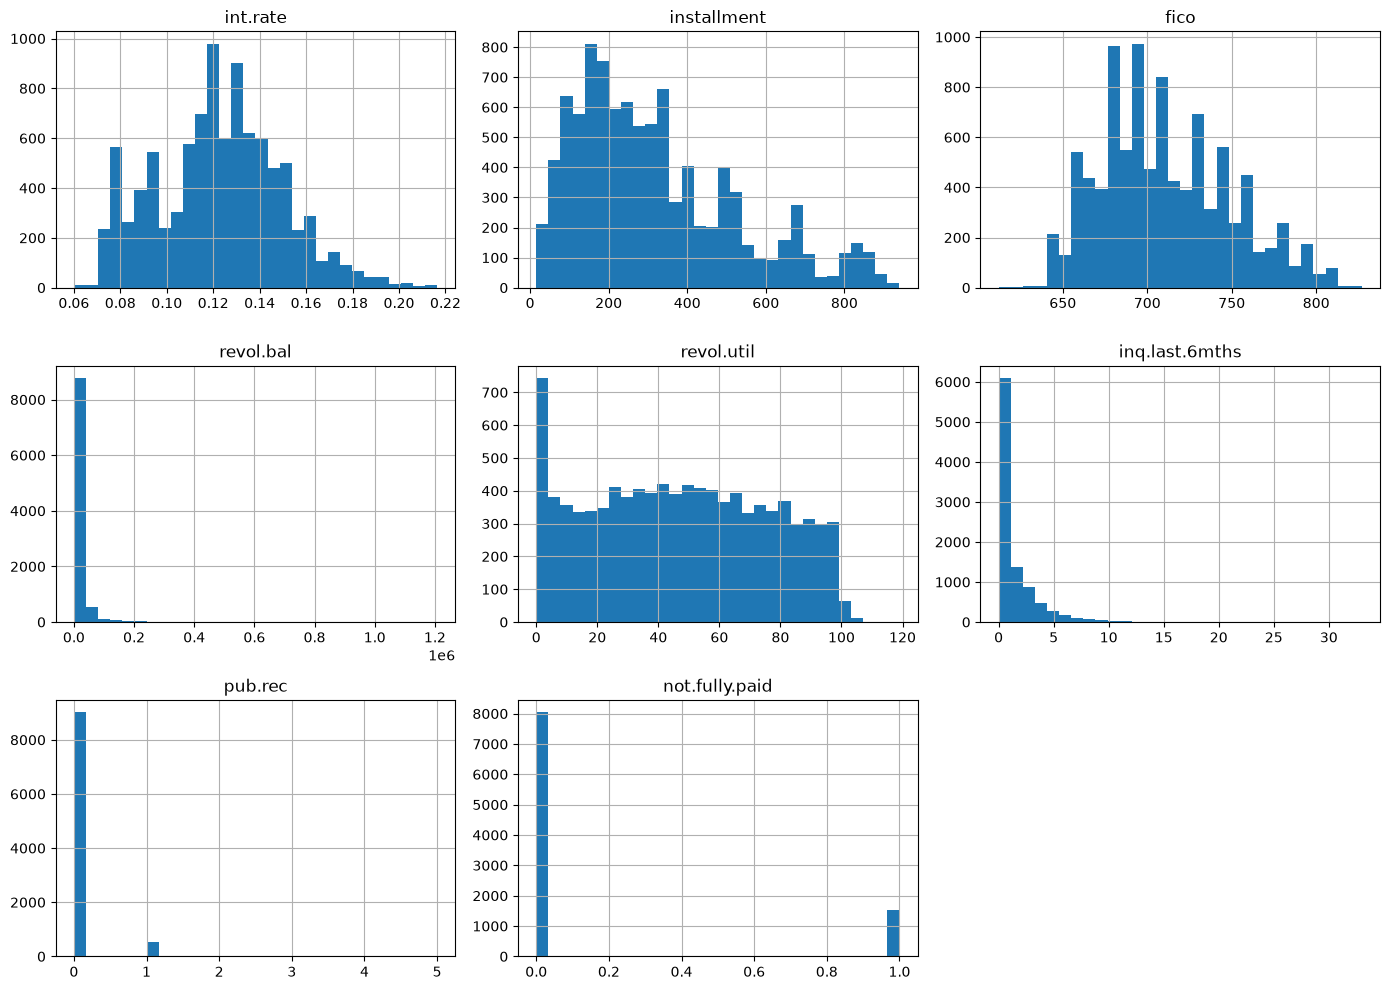

purpose
debt_consolidation    3957
all_other             2331
credit_card           1262
home_improvement       629
small_business         619
major_purchase         437
educational            343
Name: count, dtype: int64


KeyError: "['credit.policy', 'delinq.2yrs', 'log.annual.inc', 'days.with.cr.line', 'dti'] not found in axis"

In [ ]:
print(loan_data.shape)
print(loan_data.info())
display(loan_data.describe())

matriz_correlacion = loan_data.corr(numeric_only=True)
display(matriz_correlacion.style.background_gradient())

loan_data.hist(bins=30, figsize=(14, 10))
plt.tight_layout()
plt.show()

columnas_a_eliminar = [
    "credit.policy",
    'delinq.2yrs',
    'log.annual.inc', 
    'days.with.cr.line', 
    'dti',
]

loan_data = loan_data.drop(columnas_a_eliminar, axis=1)

#### DIVIDIR LOS DATOS

In [20]:
# Queremos que la proporción de prestamos que se pagan y de los que no sea similar, para asegurarlo, estratificamos por ese campo
train_set, test_set = train_test_split(loan_data, train_size=0.85, stratify=loan_data["not.fully.paid"], random_state=42)

#### PREPARAR LOS DATOS

In [21]:
numeric_pipeline = make_pipeline(
    SimpleImputer(strategy="median"),
    StandardScaler(),
)

categoric_pipeline = make_pipeline(
    SimpleImputer(strategy="most_frequent"),
    OneHotEncoder(handle_unknown="ignore", sparse_output=False),
)

preprocessing = ColumnTransformer([
    ("numeric", numeric_pipeline, ["int.rate", "installment", "fico", "revol.bal", "revol.util", "inq.last.6mths", "pub.rec"]),
    ("categories", categoric_pipeline, ["purpose"]),
])

y_train = train_set["not.fully.paid"]
X_train = train_set.drop(columns="not.fully.paid")

y_test = test_set["not.fully.paid"]
X_test = test_set.drop(columns="not.fully.paid")

### ENTRENAMIENTO Y EVALUACIÓN DEL MODELO

Usa evaluación cruzada con los siguientes algoritmos:
- Regresión logisitca
- SGDClassifier
- K vecinos mas cercanos
- Random Forest

 y evalua los resultados en el conjunto de entrenamiento con las siguientes métricas: exactitud, prescisión, sensibilidad, f1, curva de roc y área bajo la curva de roc

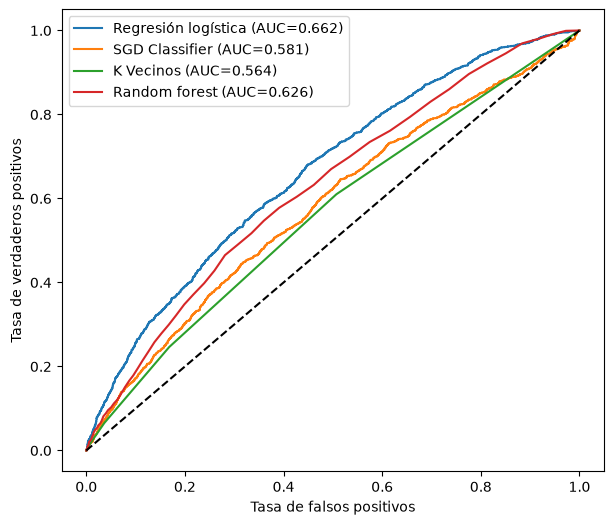

,exactitud,precisión,sensibilidad,f1,auc
Regresión logística,0.8404,0.5357,0.0230,0.0442,0.6624
SGD Classifier,0.8398,0.4000,0.0015,0.0031,0.5809
K Vecinos,0.8198,0.2545,0.0652,0.1038,0.5637
Random forest,0.8354,0.3391,0.0299,0.0550,0.6263


In [22]:
# Modelos a comparar: cada uno es un pipeline (preprocesado + clasificador)
pipeline_regresion_logistica = make_pipeline(preprocessing, LogisticRegression(max_iter=1000))
pipeline_sgd = make_pipeline(preprocessing, SGDClassifier(random_state=42))
pipeline_knn = make_pipeline(preprocessing, KNeighborsClassifier())
pipeline_random_forest = make_pipeline(preprocessing, RandomForestClassifier(random_state=42))


def evaluar_modelo(nombre_modelo, pipeline, X_train, y_train):
    # Clases predichas: para exactitud, precisión, sensibilidad y F1
    clases_predichas = cross_val_predict(pipeline, X_train, y_train, cv=3)

    # Puntuaciones: para la curva ROC y el AUC (Area Under Curve)
    # (SGD no tiene predict_proba, así que se usa decision_function)
    if hasattr(pipeline, "predict_proba"):
        puntuaciones = cross_val_predict(
            pipeline, X_train, y_train, cv=3, method="predict_proba"
        )[:, 1]
    else:
        puntuaciones = cross_val_predict(
            pipeline, X_train, y_train, cv=3, method="decision_function"
        )

    tasa_falsos_positivos, tasa_verdaderos_positivos, _ = roc_curve(y_train, puntuaciones)
    area_bajo_curva_roc = auc(tasa_falsos_positivos, tasa_verdaderos_positivos)
    plt.plot(
        tasa_falsos_positivos,
        tasa_verdaderos_positivos,
        label=f"{nombre_modelo} (AUC={area_bajo_curva_roc:.3f})",
    )

    return {
        "exactitud": accuracy_score(y_train, clases_predichas),
        "precisión": precision_score(y_train, clases_predichas, zero_division=0),
        "sensibilidad": recall_score(y_train, clases_predichas),
        "f1": f1_score(y_train, clases_predichas),
        "auc": area_bajo_curva_roc,
    }

plt.figure(figsize=(7, 6))

metricas_por_modelo = {
    "Regresión logística": evaluar_modelo("Regresión logística", pipeline_regresion_logistica, X_train, y_train),
    "SGD Classifier": evaluar_modelo("SGD Classifier", pipeline_sgd, X_train, y_train),
    "K Vecinos": evaluar_modelo("K Vecinos", pipeline_knn, X_train, y_train),
    "Random forest": evaluar_modelo("Random forest", pipeline_random_forest, X_train, y_train),
}

plt.plot([0, 1], [0, 1], "k--")
plt.xlabel("Tasa de falsos positivos")
plt.ylabel("Tasa de verdaderos positivos")
plt.legend()
plt.show()

pd.DataFrame(metricas_por_modelo).T.round(4)


# Apuntes:
# 	                |   El modelo dice “impago”	            |    El modelo dice “pagado”
# ------------------|---------------------------------------|--------------------------------------------------
# Realmente impago  |   Verdadero positivo (VP): acierto	|    Falso negativo (FN): impago que se le escapó
# Realmente pagado	|   Falso positivo (FP): falsa alarma	|    Verdadero negativo (VN): acierto

# Exactitud: de todos los préstamos, qué proporción acierta.
# (VP + VN) / total
# Es la más intuitiva y la más engañosa aquí. Un modelo que dijera siempre “pagado” acertaría 84 de 100 (84 %) sin detectar ningún impago.

# Precisión: cuando el modelo dice “impago”, qué proporción de veces tiene razón.
# VP / (VP + FP)
# Mide la fiabilidad de las alarmas. Si es baja, el modelo marca como impagos muchos préstamos que en realidad se pagan.

# Sensibilidad (recall): de los impagos reales, qué proporción detecta.
# VP / (VP + FN)
# Mide cuántos impagos se le escapan. Si es 0,10, el modelo solo ve 1 de cada 10. En este problema suele ser la más importante, 
# porque un impago no detectado es dinero perdido. El modelo que siempre dice “pagado” tiene sensibilidad 0.

# F1: una sola nota que combina precisión y sensibilidad (su media armónica).
# 2 · precisión · sensibilidad / (precisión + sensibilidad)
# Hace falta porque las dos se compensan: si el modelo marca todo como impago, la sensibilidad es 1 pero la precisión es mínima. 
# La media armónica solo sale alta si ambas lo son, así que un valor bajo en una de las dos arrastra el F1.

### OPMITZACIÓN DEL MODELO

#### OPTIMIZACIÓN

Usa búsqueda exhaustiva o búsqueda aleatoria para optimizar el mejor modelo del apartado anterior

In [23]:
from scipy.stats import loguniform

parametros_grid_search = {
    "logisticregression__C": [0.001, 0.01, 0.1, 1, 10, 100],
    "logisticregression__solver": ['lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga']
}

parametros_randomized_search = {
    "logisticregression__C": loguniform(1e-3, 1e2),
    "logisticregression__solver": ['lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga']
}

grid_search = GridSearchCV(
    estimator=pipeline_regresion_logistica, 
    param_grid=parametros_grid_search,
    cv=3,
    scoring="roc_auc"
)
grid_search.fit(X_train, y_train)

randomized_search = RandomizedSearchCV(
    estimator=pipeline_regresion_logistica,
    param_distributions=parametros_randomized_search,
    cv=3,
    scoring="roc_auc",
    random_state=42,
)
randomized_search.fit(X_train, y_train)


print(grid_search.best_params_)
print(randomized_search.best_params_)

/home/iabd/raumel/sapa/IABD-SAPA-Aprendizaje_supervisado/.venv/lib/python3.14/site-packages/sklearn/linear_model/_sag.py:348: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
/home/iabd/raumel/sapa/IABD-SAPA-Aprendizaje_supervisado/.venv/lib/python3.14/site-packages/sklearn/linear_model/_sag.py:348: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(


{'logisticregression__C': 0.1, 'logisticregression__solver': 'liblinear'}
{'logisticregression__C': np.float64(0.0745934328572655), 'logisticregression__solver': 'sag'}


#### EVALUACIÓN EN EL CONJUNTO DE PRUEBA

Evalúa el conjunto de pruebas con diferentes métricas

/home/iabd/raumel/sapa/IABD-SAPA-Aprendizaje_supervisado/.venv/lib/python3.14/site-packages/sklearn/linear_model/_sag.py:348: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
/home/iabd/raumel/sapa/IABD-SAPA-Aprendizaje_supervisado/.venv/lib/python3.14/site-packages/sklearn/linear_model/_sag.py:348: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
/home/iabd/raumel/sapa/IABD-SAPA-Aprendizaje_supervisado/.venv/lib/python3.14/site-packages/sklearn/linear_model/_sag.py:348: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
/home/iabd/raumel/sapa/IABD-SAPA-Aprendizaje_supervisado/.venv/lib/python3.14/site-packages/sklearn/linear_model/_sag.py:348: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
/home/iabd/raumel/sapa/IABD-SAPA-Aprendizaje_supervisado/.venv/lib/python3.14/site-packages/

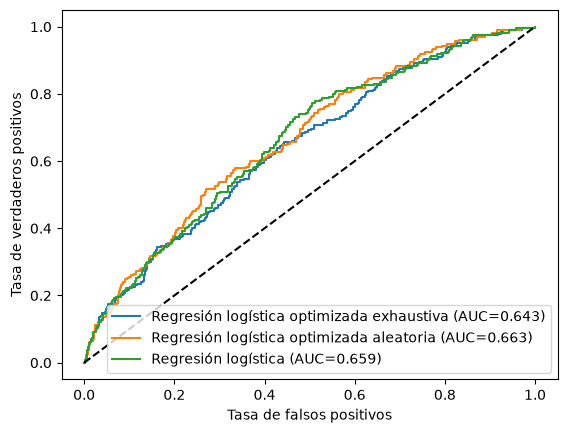

,exactitud,precisión,sensibilidad,f1,auc
Regresión logística optimizada exhaustiva,0.8386,0.4286,0.0261,0.0492,0.6429
Regresión logística optimizada aleatoria,0.8379,0.4000,0.0261,0.0490,0.6634
Regresión logística,0.8392,0.4762,0.0435,0.0797,0.6591


In [ ]:
metricas_por_modelo = {
    "Regresión logística optimizada exhaustiva": evaluar_modelo("Regresión logística optimizada exhaustiva", grid_search.best_estimator_, X_test, y_test),
    "Regresión logística optimizada aleatoria": evaluar_modelo("Regresión logística optimizada aleatoria", randomized_search.best_estimator_, X_test, y_test),
    "Regresión logística": evaluar_modelo("Regresión logística", pipeline_regresion_logistica, X_test, y_test),
}

plt.plot([0, 1], [0, 1], "k--")
plt.xlabel("Tasa de falsos positivos")
plt.ylabel("Tasa de verdaderos positivos")
plt.legend()
plt.show()

pd.DataFrame(metricas_por_modelo).T.round(4)

### PRESENTACIÓN DE LA SOLUCIÓN

Guarda mejor modelo (pipeline de preparación de los datos + modelo) y  haz un script de python que te pida los datos necesarios ('int_rate', 'installment', 'fico',  'revol_bal', 'revol_util', 'inq_last_6mths', 'pub_rec' y 'purpose') y prediga la solución.

In [27]:
import os

if not os.path.exists('./Resultados'):
    os.makedirs('./Resultados')

modelo_final = randomized_search.best_estimator_

joblib.dump(modelo_final, "Resultados/modelo_final_prestamos.joblib")

['Resultados/modelo_final_prestamos.joblib']

## EJERCICIO 2

Vamos a trabajar conun conjunto de datos digits.

Crea un clasificador que nos diga de que número se trata.

### RECOPILACIÓN Y PREPARACIÓN DE LOS DATOS

#### OBTENER LOS DATOS

In [ ]:
# Cargar el conjunto de datos
digits = load_digits()
X_digits = digits.data
y_digits = digits.target

#### EXPLORAR LOS DATOS

#### DIVIDIR LOS DATOS

#### PREPARAR LOS DATOS

### ENTRENAMIENTO Y EVALUACIÓN DEL MODELO

Usa evaluación cruzada con los siguientes algoritmos, evalua los resultados en el conjunto de entrenamiento (exactitud) y calcula la matriz de confusión:
- Regresión logistica
- Maquinas de vectores de sorpote
- Random forest

### OPMITZACIÓN DEL MODELO

#### OPTIMIZACIÓN

Usa búsqueda exhaustiva o búsqueda aleatoria para optimizar el mejor modelo del apartado anterior

#### EVALUACIÓN EN EL CONJUNTO DE PRUEBA

### PRESENTACIÓN DE LA SOLUCIÓN

Simplemente guarda el modelo